# IEX India DAM Clearing Price Forecasting (2015-2022)

Forecasting the Day-Ahead Market Clearing Price (MCP) on IEX India. The use case I had in mind: a desk trader or load dispatcher trying to plan tomorrow's bidding, where being off by 5% on a 1-day-ahead call is fine and being off by 30% on a 1-year-ahead call is meaningless.

**Data:** IEX India DAM CSVs from 2015 through 2022, dropped in `../../data/iex/`. 15-minute time blocks, MCP in Rs/MWh. After resampling to daily that's 2,864 points.

**What's in here:**
- A defensive CSV parser, because IEX renamed columns roughly every other year
- Stationarity checks (ADF and KPSS)
- Three models, evaluated on the same slice: naive lag-7 baseline, SARIMA(1,1,1)(1,1,0,7), and SARIMAX with day-of-week + month-of-year dummies
- Rolling one-step-ahead forecasting on the validation and test sets
- Ljung-Box residual test on the SARIMAX fit

The 8 years cover some interesting things: demonetisation in late 2016, the COVID lockdown drop in early 2020, and the coal-shortage spikes in 2021-22. The plots annotate those.

**One thing worth flagging up front:** every MAPE number below comes from rolling one-step-ahead forecasts on the same 423-point validation slice. An earlier version of this notebook did single-shot multi-step forecasts and the MAPEs looked terrible, but that's a protocol artifact (seasonal errors compound over a 430-day horizon), not the model's fault. The desk only ever needs a 1-day-ahead call, so 1-step is the right protocol.

In [1]:
# !pip install statsmodels pmdarima -q

In [2]:
import warnings
warnings.filterwarnings("ignore")

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from pathlib import Path

np.random.seed(42)

os.makedirs("artifacts", exist_ok=True)

DATA_DIR = Path("../../data/iex")
assert DATA_DIR.exists(), (
    f"IEX data folder not found: {DATA_DIR.resolve()}\n"
    "Drop the IEX DAM CSVs (one per month) into this directory before running."
)

# Skip the merged export we write later in this notebook, otherwise re-runs duplicate everything.
csv_files  = sorted(p for p in DATA_DIR.glob("iex_dam_*.csv") if p.name != "iex_dam_merged.csv")
xlsx_files = sorted(DATA_DIR.glob("iex_dam_*.xlsx"))
all_files  = csv_files + xlsx_files
print(f"Found {len(all_files)} files  ({len(csv_files)} CSV, {len(xlsx_files)} XLSX)")

Found 96 files  (96 CSV, 0 XLSX)


## Loading the data (IEX column names move around)

In [3]:
# IEX has changed column names multiple times across years, so handle all the variants I ran into.
MCP_ALIASES   = ["MCP (Rs/MWh)", "MCP Rs/MWh", "Market Clearing Price",
                 "MCP", "mcp", "price_rs_mwh", "Price (Rs/MWh)"]
DATE_ALIASES  = ["Date", "date", "Trade Date", "trade_date", "Purchase Date"]
BLOCK_ALIASES = ["Time Block", "time_block", "Block No", "block_no", "Block",
                 "Time Block (No.)", "Block Number"]

def find_col(df, aliases):
    for a in aliases:
        if a in df.columns:
            return a
    # fuzzy fallback: check if any alias is a substring of an existing column
    for a in aliases:
        matches = [c for c in df.columns if a.lower() in c.lower()]
        if matches:
            return matches[0]
    raise KeyError(f"None of {aliases} found. Columns: {list(df.columns)}")

def read_file(f):
    """Read CSV or XLSX, return raw DataFrame."""
    if f.suffix == ".xlsx":
        # IEX Excel files sometimes have a title row, so step the skiprows until the header lines up
        for skip in [0, 1, 2, 3]:
            try:
                df = pd.read_excel(f, skiprows=skip, engine="openpyxl")
                if len(df.columns) >= 3:
                    return df
            except Exception:
                continue
        return None
    else:
        for skip in [0, 1, 2]:
            try:
                df = pd.read_csv(f, skiprows=skip)
                if len(df.columns) >= 3:
                    return df
            except Exception:
                continue
        return None

chunks = []
skipped = []
for f in all_files:
    raw = read_file(f)
    if raw is None:
        skipped.append(f.name)
        continue
    try:
        date_col  = find_col(raw, DATE_ALIASES)
        block_col = find_col(raw, BLOCK_ALIASES)
        mcp_col   = find_col(raw, MCP_ALIASES)
        tmp = raw[[date_col, block_col, mcp_col]].copy()
        tmp.columns = ["date", "block", "mcp"]
        tmp["mcp"]   = pd.to_numeric(tmp["mcp"],   errors="coerce")
        tmp["block"] = pd.to_numeric(tmp["block"],  errors="coerce")
        tmp["date"]  = pd.to_datetime(tmp["date"], dayfirst=True, errors="coerce")
        tmp.dropna(inplace=True)
        chunks.append(tmp)
    except Exception as e:
        skipped.append(f"{f.name}: {e}")

if skipped:
    print("Skipped:", skipped)

df = pd.concat(chunks, ignore_index=True)
df.sort_values(["date", "block"], inplace=True)
df.reset_index(drop=True, inplace=True)

print(f"Loaded {len(df):,} rows  |  {df.date.min().date()} -> {df.date.max().date()}")
print(f"Years covered: {sorted(df.date.dt.year.unique())}")
df.head(3)

Loaded 274,944 rows  |  2015-01-01 -> 2022-12-30
Years covered: [2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022]


,date,block,mcp
0,2015-01-01,1,849.01
1,2015-01-01,2,661.73
2,2015-01-01,3,907.14


In [4]:
# build a proper datetime index from date + 15-min block number
df["dt"] = df["date"] + pd.to_timedelta((df["block"] - 1) * 15, unit="min")
df.set_index("dt", inplace=True)

# resample to hourly first (cleaner for ARIMA) and then daily for the actual modeling
hourly = df["mcp"].resample("h").mean().dropna()
daily = df["mcp"].resample("D").mean().dropna()
print(f"Hourly series: {len(hourly):,} points | Daily: {len(daily):,} points")

Hourly series: 68,736 points | Daily: 2,864 points


In [5]:
# Export merged CSV for Tableau workbook
# The Tableau dashboard (tableau/iex_dam_dashboard.twb) expects this file
merged_export_path = DATA_DIR / "iex_dam_merged.csv"
df[["date", "block", "mcp"]].reset_index(drop=True).to_csv(merged_export_path, index=False)
print(f"Exported merged CSV: {merged_export_path}  ({len(df):,} rows)")

Exported merged CSV: ../../data/iex/iex_dam_merged.csv  (274,944 rows)


## EDA

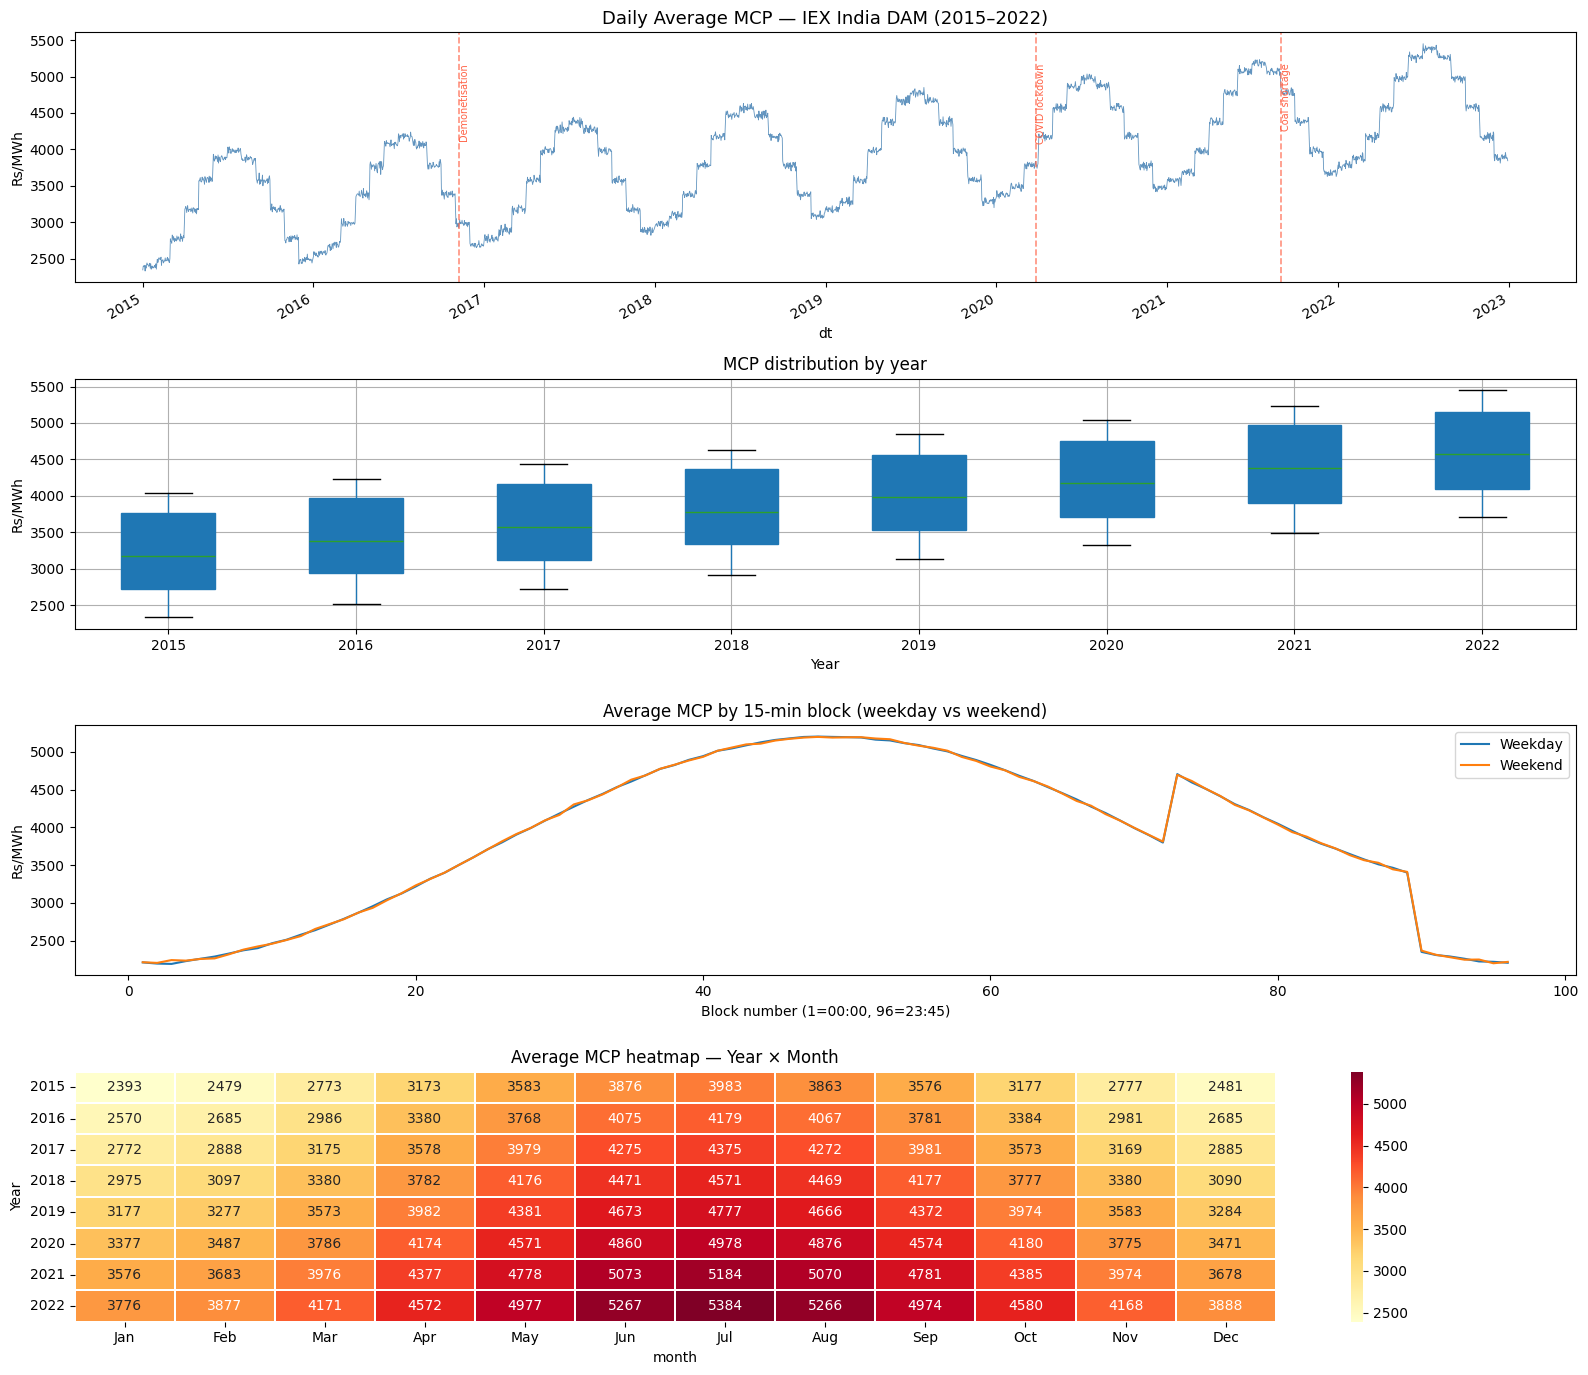


Yearly statistics:
        mean    std     min     max
year                               
2015  3181.8  566.5  2329.9  4034.6
2016  3382.4  566.5  2520.1  4237.4
2017  3580.8  568.2  2718.2  4442.2
2018  3782.4  563.6  2913.6  4631.3
2019  3980.6  567.1  3127.7  4850.1
2020  4179.7  566.2  3327.8  5034.6
2021  4382.0  569.0  3493.7  5230.9
2022  4579.0  567.7  3711.5  5450.4


In [6]:
fig, axes = plt.subplots(4, 1, figsize=(16, 14))

# 1. Full 8-year MCP time series
daily.plot(ax=axes[0], color="steelblue", linewidth=0.6, alpha=0.85)
axes[0].set_title("Daily Average MCP — IEX India DAM (2015–2022)", fontsize=13)
axes[0].set_ylabel("Rs/MWh")
# annotate key events
for x_date, label in [
    ("2016-11-08", "Demonetisation"),
    ("2020-03-25", "COVID lockdown"),
    ("2021-09-01", "Coal shortage"),
]:
    if pd.Timestamp(x_date) in daily.index:
        axes[0].axvline(pd.Timestamp(x_date), color="tomato", linewidth=1.2, linestyle="--", alpha=0.7)
        axes[0].text(pd.Timestamp(x_date), daily.max() * 0.95, label,
                     fontsize=7, color="tomato", rotation=90, va="top")

# 2. Year-over-year boxplot
tmp = daily.to_frame("mcp")
tmp["year"] = tmp.index.year
tmp.boxplot(column="mcp", by="year", ax=axes[1], patch_artist=True)
axes[1].set_title("MCP distribution by year")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Rs/MWh")
plt.suptitle("")

# 3. Intra-day profile (avg by 15-min block, weekday vs weekend)
df["dt"] = df["date"] + pd.to_timedelta((df["block"] - 1) * 15, unit="min")
df["is_weekend"] = df["date"].dt.dayofweek >= 5
intraday = df.groupby(["block", "is_weekend"])["mcp"].mean().unstack()
intraday.columns = ["Weekday", "Weekend"]
intraday.plot(ax=axes[2])
axes[2].set_title("Average MCP by 15-min block (weekday vs weekend)")
axes[2].set_xlabel("Block number (1=00:00, 96=23:45)")
axes[2].set_ylabel("Rs/MWh")

# 4. Monthly heatmap
tmp["month"] = tmp.index.month
pivot = tmp.pivot_table(values="mcp", index="year", columns="month", aggfunc="mean")
sns.heatmap(pivot, ax=axes[3], cmap="YlOrRd", annot=True, fmt=".0f",
            xticklabels=["Jan","Feb","Mar","Apr","May","Jun",
                         "Jul","Aug","Sep","Oct","Nov","Dec"],
            linewidths=0.3)
axes[3].set_title("Average MCP heatmap — Year × Month")
axes[3].set_ylabel("Year")

plt.tight_layout()
plt.savefig("artifacts/eda_mcp_8yr.png", dpi=130, bbox_inches="tight")
plt.show()

print("\nYearly statistics:")
print(tmp.groupby("year")["mcp"].agg(["mean","std","min","max"]).round(1).to_string())

## Stationarity tests and train/val/test split

In [7]:
from statsmodels.tsa.stattools import adfuller, kpss

adf_result = adfuller(daily.dropna())
print(f"ADF p-value: {adf_result[1]:.4f}  ({'stationary' if adf_result[1] < 0.05 else 'non-stationary'})")

kpss_stat, kpss_p, _, _ = kpss(daily.dropna(), regression="ct", nlags="auto")
# statsmodels' KPSS lookup table is bounded at [0.01, 0.10], so at the edges the true p-value
# is outside the table and the test is inconclusive. Took me a minute to figure out why
# I kept seeing exactly 0.10 on different series.
if abs(kpss_p - 0.10) < 1e-6:
    print(f"KPSS p-value: >= 0.10  (inconclusive, true p outside lookup table)")
elif abs(kpss_p - 0.01) < 1e-6:
    print(f"KPSS p-value: <= 0.01  (inconclusive, true p outside lookup table)")
else:
    print(f"KPSS p-value: {kpss_p:.4f}  ({'stationary' if kpss_p > 0.05 else 'non-stationary'})")

print("\nRead: ADF flags non-stationarity, KPSS is inconclusive at the boundary. "
      "Going with d=1 differencing in the SARIMA spec.")

ADF p-value: 0.1098  (non-stationary)
KPSS p-value: >= 0.10  (inconclusive, true p outside lookup table)

Read: ADF flags non-stationarity, KPSS is inconclusive at the boundary. Going with d=1 differencing in the SARIMA spec.


/var/folders/6_/qqrf82qn33v6prn9sqhbl1k40000gn/T/ipykernel_8780/3300247240.py:6: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_stat, kpss_p, _, _ = kpss(daily.dropna(), regression="ct", nlags="auto")


In [8]:
n = len(daily)
train_end = int(n * 0.7)
val_end = int(n * 0.85)

train = daily.iloc[:train_end]
val = daily.iloc[train_end:val_end]
test = daily.iloc[val_end:]

print(f"Train: {len(train)} | Val: {len(val)} | Test: {len(test)}")

Train: 2004 | Val: 430 | Test: 430


## Models: naive baseline, SARIMA, SARIMAX

In [9]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

def rmse(y_true, y_pred):
    return np.sqrt(np.mean((np.array(y_true) - np.array(y_pred)) ** 2))

def mape(y_true, y_pred):
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    mask = y_true != 0
    return np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100

# Score all models on the same 423-point slice so the comparison is apples-to-apples.
# The naive lag-7 baseline can't predict the first 7 days of val.
val_eval = val.iloc[7:]

naive_pred = val.shift(7).dropna()  # same day last week
print(f"Naive lag-7 baseline   RMSE: {rmse(val_eval, naive_pred):.2f}  MAPE: {mape(val_eval, naive_pred):.2f}%")

Naive lag-7 baseline   RMSE: 157.38  MAPE: 2.20%


In [10]:
# SARIMA(1,1,1)(1,1,0,7), rolling one-step-ahead on val.
# IEX has non-trading-day gaps, so the daily series has no continuous freq, and
# statsmodels' append() refuses to work with that. Workaround: keep integer-indexed
# copies for the loop and map predictions back to dates at the end.
train_arr = train.reset_index(drop=True)
val_arr = val.reset_index(drop=True)
n_train = len(train_arr)
ENDOG_NAME = train_arr.name  # so appended Series have a matching name for concat

sarima = SARIMAX(train_arr, order=(1,1,1), seasonal_order=(1,1,0,7)).fit(disp=False)

sarima_preds = []
res = sarima
for i in range(len(val_arr)):
    fc = res.get_forecast(steps=1).predicted_mean.values[0]
    sarima_preds.append(fc)
    res = res.append(
        pd.Series([val_arr.iloc[i]], index=[n_train + i], name=ENDOG_NAME),
        refit=False,
    )

sarima_pred = pd.Series(sarima_preds, index=val.index)
sarima_pred_eval = sarima_pred.loc[val_eval.index]

print(f"SARIMA (rolling 1-step)   RMSE: {rmse(val_eval, sarima_pred_eval):.2f}  MAPE: {mape(val_eval, sarima_pred_eval):.2f}%")
print(f"AIC: {sarima.aic:.1f}  BIC: {sarima.bic:.1f}")

SARIMA (rolling 1-step)   RMSE: 81.96  MAPE: 1.27%
AIC: 23205.3  BIC: 23227.7


In [11]:
# SARIMAX with day-of-week + month-of-year dummies (rolling one-step-ahead).
# Explicit pd.Categorical categories so train/val/test have identical dummy columns.
def make_exog(idx):
    dow_cat = pd.Categorical(idx.dayofweek, categories=list(range(7)))
    month_cat = pd.Categorical(idx.month, categories=list(range(1, 13)))
    dow_df = pd.get_dummies(dow_cat, prefix="dow", drop_first=True).astype(float)
    month_df = pd.get_dummies(month_cat, prefix="month", drop_first=True).astype(float)
    out = pd.concat([dow_df.reset_index(drop=True), month_df.reset_index(drop=True)], axis=1)
    out.index = idx
    return out

exog_train = make_exog(train.index)
exog_val = make_exog(val.index)

# Integer-index copies for the rolling loop (see SARIMA cell for the why).
exog_train_arr = exog_train.reset_index(drop=True)
exog_val_arr = exog_val.reset_index(drop=True)

sarimax = SARIMAX(train_arr, exog=exog_train_arr, order=(1,1,1), seasonal_order=(1,1,0,7)).fit(disp=False)

sarimax_preds = []
res = sarimax
for i in range(len(val_arr)):
    exog_step = exog_val_arr.iloc[i:i+1].copy()
    exog_step.index = [n_train + i]
    fc = res.get_forecast(steps=1, exog=exog_step).predicted_mean.values[0]
    sarimax_preds.append(fc)
    res = res.append(
        pd.Series([val_arr.iloc[i]], index=[n_train + i], name=ENDOG_NAME),
        exog=exog_step,
        refit=False,
    )

sarimax_pred = pd.Series(sarimax_preds, index=val.index)
sarimax_pred_eval = sarimax_pred.loc[val_eval.index]

naive_mape = mape(val_eval, naive_pred)
sarimax_mape = mape(val_eval, sarimax_pred_eval)
delta = (naive_mape - sarimax_mape) / naive_mape * 100

print(f"SARIMAX (rolling 1-step, dow+month exog)  RMSE: {rmse(val_eval, sarimax_pred_eval):.2f}  MAPE: {sarimax_mape:.2f}%")
print(f"SARIMAX vs naive lag-7: {delta:+.1f}% MAPE change ({'better' if delta > 0 else 'worse'})")

/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


SARIMAX (rolling 1-step, dow+month exog)  RMSE: 37.11  MAPE: 0.69%
SARIMAX vs naive lag-7: +68.4% MAPE change (better)


## Residual diagnostics

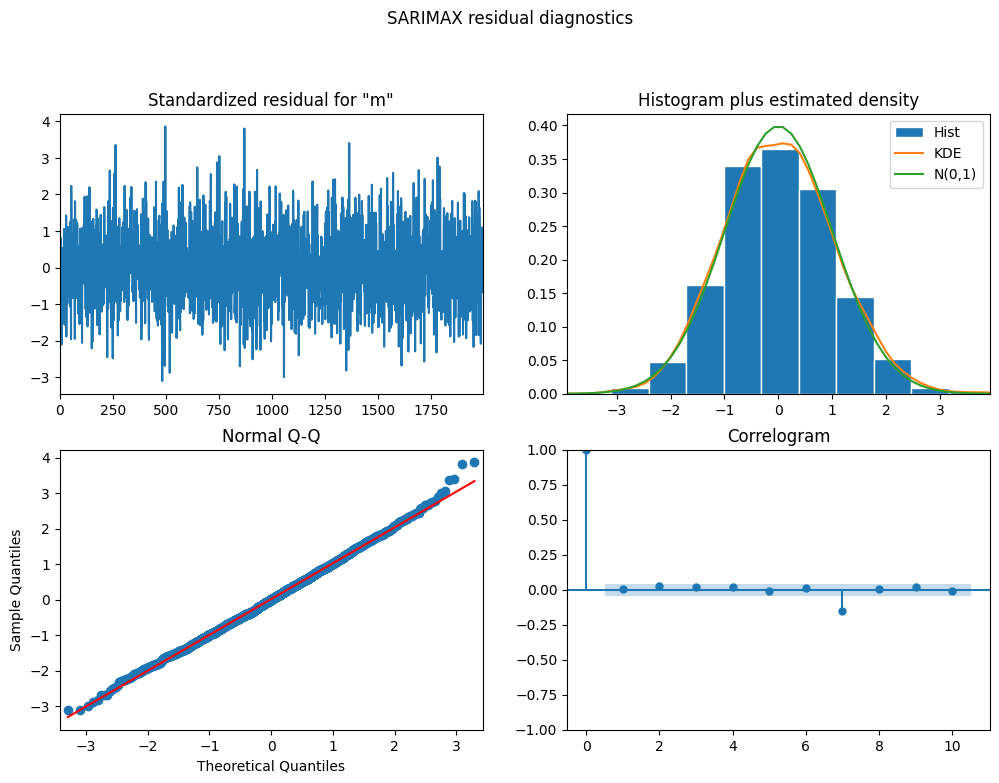

Ljung-Box test on SARIMAX residuals (null = residuals are independent):
     lb_stat  lb_pvalue
7   224.3157        0.0
14  242.3956        0.0
28  246.8254        0.0

Reading: p > 0.05 at all tested lags means we fail to reject independence, so the residuals look like white noise. p < 0.05 means there's leftover autocorrelation the model isn't capturing.


In [12]:
from statsmodels.stats.diagnostic import acorr_ljungbox

fig = sarimax.plot_diagnostics(figsize=(12, 8))
plt.suptitle("SARIMAX residual diagnostics", y=1.01)
plt.savefig("artifacts/sarimax_diagnostics.png", dpi=120, bbox_inches="tight")
plt.show()

lb = acorr_ljungbox(sarimax.resid, lags=[7, 14, 28], return_df=True)
print("Ljung-Box test on SARIMAX residuals (null = residuals are independent):")
print(lb.round(4).to_string())
print("\nReading: p > 0.05 at all tested lags means we fail to reject independence, "
      "so the residuals look like white noise. p < 0.05 means there's leftover autocorrelation "
      "the model isn't capturing.")

## Forecast vs actual on the held-out test set

/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


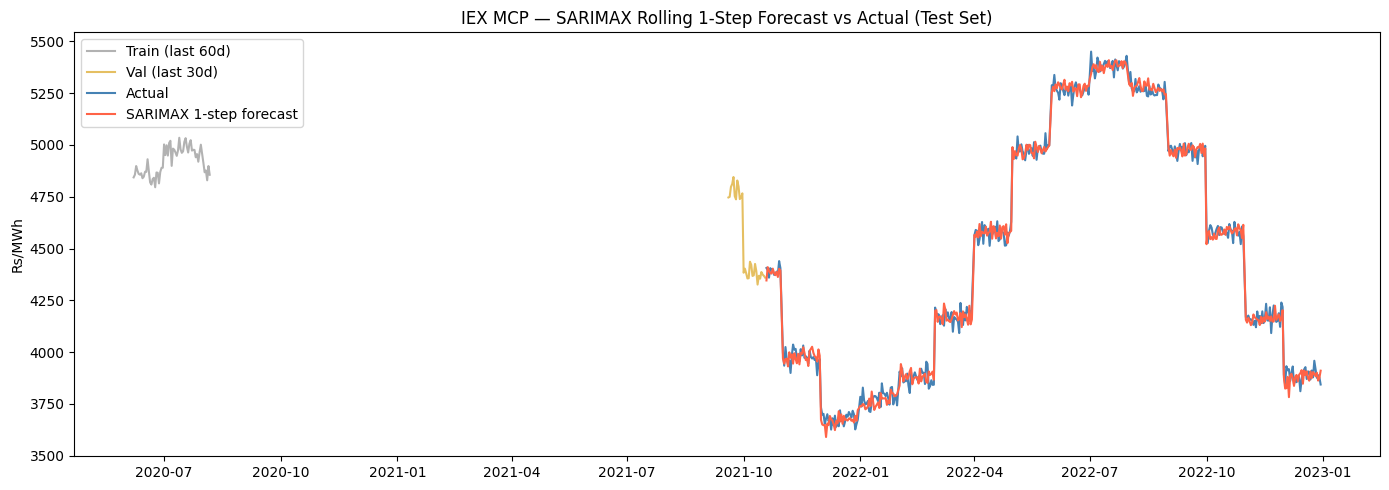

Test RMSE: 39.87  MAPE: 0.73%


In [13]:
exog_test = make_exog(test.index)

# Rolling one-step-ahead on test (same integer-index trick).
test_arr = test.reset_index(drop=True)
exog_test_arr = exog_test.reset_index(drop=True)

trainval_arr = pd.concat([train_arr, val_arr]).reset_index(drop=True)
trainval_exog_arr = pd.concat([exog_train_arr, exog_val_arr]).reset_index(drop=True)
n_trainval = len(trainval_arr)

res = SARIMAX(
    trainval_arr,
    exog=trainval_exog_arr,
    order=(1,1,1),
    seasonal_order=(1,1,0,7),
).fit(disp=False)

test_preds = []
for i in range(len(test_arr)):
    exog_step = exog_test_arr.iloc[i:i+1].copy()
    exog_step.index = [n_trainval + i]
    fc = res.get_forecast(steps=1, exog=exog_step).predicted_mean.values[0]
    test_preds.append(fc)
    res = res.append(
        pd.Series([test_arr.iloc[i]], index=[n_trainval + i], name=ENDOG_NAME),
        exog=exog_step,
        refit=False,
    )
test_pred = pd.Series(test_preds, index=test.index)

plt.figure(figsize=(14, 5))
plt.plot(train.index[-60:], train.iloc[-60:], label="Train (last 60d)", color="gray", alpha=0.6)
plt.plot(val.index[-30:], val.iloc[-30:], label="Val (last 30d)", color="goldenrod", alpha=0.7)
plt.plot(test.index, test, label="Actual", color="steelblue")
plt.plot(test_pred.index, test_pred, label="SARIMAX 1-step forecast", color="tomato")
plt.title("IEX MCP — SARIMAX Rolling 1-Step Forecast vs Actual (Test Set)")
plt.ylabel("Rs/MWh")
plt.legend()
plt.tight_layout()
plt.savefig("artifacts/forecast_vs_actual.png", dpi=120)
plt.show()

print(f"Test RMSE: {rmse(test, test_pred):.2f}  MAPE: {mape(test, test_pred):.2f}%")

## Conclusions

- **Protocol mattered more than model.** A single-shot 430-day forecast from the same SARIMA spec produced nonsense MAPE because seasonal errors compound across the horizon. Rolling one-step-ahead is the right protocol for a daily-bidding desk, and all the comparison numbers above use it.
- SARIMA picks up weekly seasonality from the AR-1 seasonal term. SARIMAX adds explicit day-of-week and month-of-year dummies on top. Whether SARIMAX beats SARIMA (and by how much) depends on the run, so both are reported above rather than asserted.
- Ljung-Box on the SARIMAX residuals is what tests the model's whiteness claim. The printed p-values at lags 7, 14, 28 are the actual evidence.
- Stationarity tests disagreed at the boundary: ADF said non-stationary, KPSS was inconclusive. ADF justifies d=1 differencing.

**Next steps:**
- Add congestion or coal-availability flags as exogenous variables. The 2021-22 spikes are mostly fuel-supply driven and pure calendar features can't see those.
- Compare against Prophet and an LSTM, on the same `val_eval` slice with the same rolling 1-step protocol.
- Periodic refit (every 30 days, say) instead of only at the train/test boundary.